# Проект. Исследование стартапов

## Контекст проекта
Финансовая компания, специализирующаяся на венчурных инвестициях, ставит перед собой задачу понять закономерности финансирования стартапов и оценить перспективы выхода на рынок. Для этого необходимо провести исследование на основе исторических данных о компаниях, объемах и типах привлеченных инвестиций, а также дополнительной статистике по возвратам средств. Анализ позволит сформулировать рекомендации для принятия обоснованных инвестиционных стратегических решений.

## Цель проекта
Целью данного проекта является комплексный анализ датасета о венчурных инвестициях и данных о возвратах. В ходе работы необходимо:
- Подготовить данные к исследованию.
- Исследовать структуру и динамику финансирования стартапов во временном разрезе.
- Оценить популярность различных типов финансирования и их эффективность.
- По итогам анализа дать рекомендации о том, куда и каким образом было бы целесообразно инвестировать, если бы на календаре был 2015 год.

## Этапы работы
Исследование будет проводиться по следующему плану:
1. Загрузка и предобработка данных.
2. Инжиниринг признаков.
3. Анализ выбросов и динамики.
4. Анализ возвратов.
5. Формулировка итоговых выводов и рекомендаций.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


### 1.1. Вывод общей информации

Загрузим необходимые для работы библиотеки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

pd.set_option('display.max_columns', None)

Загрузим все данные по проекту.

In [2]:
df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)

df.head(3)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
df_returns = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv", sep=',')

df_returns.head(3)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0


Выведем информацию, которая необходима для принятия решений о предобработке.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("Доля пропусков по столбцам (%):")
print(missing_percentage.sort_values(ascending=False))

Доля пропусков по столбцам (%):
state_code              44.448742
mid_funding_at          44.214830
participants            43.874093
founded_month           29.122923
founded_quarter         29.122923
founded_at              28.990312
founded_year            28.990312
city                    20.208494
country_code            18.655837
region                  18.655837
category_list           16.239363
 market                 16.239363
homepage_url            15.296350
status                  11.364055
name                     8.945740
private_equity           8.943898
round_E                  8.943898
round_F                  8.943898
round_D                  8.943898
round_C                  8.943898
round_G                  8.943898
round_B                  8.943898
round_A                  8.943898
product_crowdfunding     8.943898
secondary_market         8.943898
post_ipo_debt            8.943898
post_ipo_equity          8.943898
venture                  8.943898
grant           

In [6]:
duplicates_count = df.duplicated().sum()
print(f"Количество полных дубликатов строк: {duplicates_count}")

Количество полных дубликатов строк: 4855


### Вывод о полученных данных

В ходе первичного знакомства с датасетом `cb_investments` были сделаны следующие наблюдения:

1. **Объём данных и соответствие описанию:** Датасет содержит 54 294 строки и 40 столбцов. Имеющиеся столбцы полностью соответствуют описанию проекта. Они включают в себя идентификационные данные, географию, категории/рынки, даты основания и финансирования, а также суммы по различным типам привлечённых инвестиций.

2. **Типы данных:** 
   * На текущий момент все столбцы, содержащие даты, имеют тип данных `object`. Для дальнейшего анализа динамики по годам их необходимо преобразовать в формат `datetime`.
   * Большинство столбцов с суммами инвестиций имеют тип `float64`, что корректно для денежных значений, однако столбец `funding_total_usd` имеет тип `object`. Это указывает на наличие текстовых разделителей, которые потребуется удалить перед переводом в числовой тип.

3. **Пропущенные значения:** 
   * Пропуски распределены неравномерно. 
   * Наибольшее количество пропусков наблюдается в геоданных, информации об участниках и в столбце с датами `mid_funding_at`.
   * Столбцы, связанные с финансированием, имеют одинаковое количество пропусков. Это важная особенность, которую необходимо учитывать.

4. **Дубликаты:** Обнаружено **4 855 полных дубликатов** строк. Это значительное количество, которое требует удаления на этапе предобработки для корректности последующих расчётов.

5. **Особенности текстовых данных:** В столбце `category_list` категории разделены символом `|`. При работе с этим столбцом стоит учитывать, что он содержит сложную структуру (список категорий), а также имеет пропуски.

**Предварительный итог:** Данные нуждаются в предобработке. Основные шаги: удаление дубликатов, преобразование типов дат и числовых столбцов, а также обработка пропусков согласно заданию.

### 1.2. Предобработка данных

Проверим названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведем их к единому аккуратному стилю.

In [7]:
print("Список названий столбцов в датасете:")
print(df.columns.tolist())

Список названий столбцов в датасете:
['name', 'homepage_url', 'category_list', ' market ', ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region', 'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month', 'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at', 'last_funding_at', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding', 'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H']


In [8]:
df = df.rename(columns={' funding_total_usd ': 'funding_total_usd'})

print(df.columns.tolist())

['name', 'homepage_url', 'category_list', ' market ', 'funding_total_usd', 'status', 'country_code', 'state_code', 'region', 'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month', 'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at', 'last_funding_at', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding', 'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H']


Уберем в столбце `funding_total_usd` выделение разрядов и приведем его к числовому типу.

In [9]:
print("Примеры значений до обработки:")
print(df['funding_total_usd'].head(10).tolist())

df['funding_total_usd'] = df['funding_total_usd'].astype(str).str.replace(' ', '').str.replace(',', '')

df['funding_total_usd'] = pd.to_numeric(df['funding_total_usd'], errors='coerce')

print("\nПримеры значений после обработки:")
print(df['funding_total_usd'].head(10).tolist())
print(f"\nТип данных после преобразования: {df['funding_total_usd'].dtype}")

Примеры значений до обработки:
[' 9,00,00,000 ', ' 20,00,000 ', ' 90,00,000 ', ' 77,00,000 ', ' 5,40,000 ', ' 1,90,00,000 ', ' 1,20,00,000 ', ' 87,00,000 ', ' 60,00,000 ', ' 35,00,000 ']

Примеры значений после обработки:
[90000000.0, 2000000.0, 9000000.0, 7700000.0, 540000.0, 19000000.0, 12000000.0, 8700000.0, 6000000.0, 3500000.0]

Тип данных после преобразования: float64


Обработаем типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [10]:
date_columns = ['founded_at', 'first_funding_at', 'last_funding_at', 'mid_funding_at']

print("Типы данных столбцов с датами ДО преобразования:")
print(df[date_columns].dtypes)

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print("\nТипы данных столбцов с датами ПОСЛЕ преобразования:")
print(df[date_columns].dtypes)

print("\nПримеры значений в столбце 'first_funding_at' после обработки:")
print(df['first_funding_at'].head(10).tolist())

Типы данных столбцов с датами ДО преобразования:
founded_at          object
first_funding_at    object
last_funding_at     object
mid_funding_at      object
dtype: object

Типы данных столбцов с датами ПОСЛЕ преобразования:
founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
last_funding_at     datetime64[ns]
mid_funding_at      datetime64[ns]
dtype: object

Примеры значений в столбце 'first_funding_at' после обработки:
[Timestamp('2014-01-06 00:00:00'), Timestamp('2014-05-15 00:00:00'), Timestamp('2009-07-02 00:00:00'), Timestamp('2013-11-21 00:00:00'), Timestamp('2014-01-14 00:00:00'), Timestamp('2014-10-23 00:00:00'), Timestamp('2013-09-05 00:00:00'), Timestamp('2014-01-12 00:00:00'), Timestamp('2014-09-30 00:00:00'), Timestamp('2007-10-01 00:00:00')]


В датасете `cb_returns` сделаем столбец `year` индексом всего датасета.

In [11]:
print("Первые 3 строки датасета cb_returns до изменения индекса:")
display(df_returns.head(3))
print(f"Текущий индекс: {df_returns.index.name}")

df_returns.set_index('year', inplace=True)

print("\nПервые 3 строки датасета cb_returns ПОСЛЕ изменения индекса:")
display(df_returns.head(3))
print(f"Новый индекс: {df_returns.index.name}")

Первые 3 строки датасета cb_returns до изменения индекса:


,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0


Текущий индекс: None

Первые 3 строки датасета cb_returns ПОСЛЕ изменения индекса:


,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0


Новый индекс: year


Обработаем текстовые данные. Пропуски в текстовых столбцах заполним заглушками там, где это понадобится.

In [12]:
df = df.rename(columns={' market ': 'market'})

df['market'] = df['market'].astype(str).str.strip()

df['market'] = df['market'].fillna('unknown')

print("Уникальные значения в столбце market (первые 10):")
print(df['market'].unique()[:10])
print(f"\nПропусков в 'market': {df['market'].isnull().sum()}")

Уникальные значения в столбце market (первые 10):
['Education' 'nan' 'Business Services' 'Social Media'
 'Hardware + Software' 'Biotechnology' 'Utilities' 'Hospitality'
 'Enterprise Software' 'Manufacturing']

Пропусков в 'market': 0


In [13]:
text_columns_to_fill = ['market', 'category_list', 'state_code', 'city', 'region']

for col in text_columns_to_fill:
    df[col] = df[col].fillna('unknown')

print("Проверка количества пропусков после замены на заглушки:")
print(df[text_columns_to_fill].isnull().sum())

print("\nУникальные значения в столбце market (первые 10):")
print(df['market'].unique()[:10])

Проверка количества пропусков после замены на заглушки:
market           0
category_list    0
state_code       0
city             0
region           0
dtype: int64

Уникальные значения в столбце market (первые 10):
['Education' 'nan' 'Business Services' 'Social Media'
 'Hardware + Software' 'Biotechnology' 'Utilities' 'Hospitality'
 'Enterprise Software' 'Manufacturing']


Обработаем полные дубликаты в данных и пропуски в `funding_total_usd`. Избавимся от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [14]:
df = df.drop_duplicates()

print(f"Количество строк после удаления дубликатов: {df.shape[0]}")

df = df.dropna(subset=['funding_total_usd'])

print(f"Количество строк после удаления пропусков в funding_total_usd: {df.shape[0]}")

df = df.dropna(how='all')

print(f"Количество строк после удаления полностью пустых строк: {df.shape[0]}")

print(f"\nОсталось пропусков в 'funding_total_usd': {df['funding_total_usd'].isnull().sum()}")

Количество строк после удаления дубликатов: 49439
Количество строк после удаления пропусков в funding_total_usd: 40907
Количество строк после удаления полностью пустых строк: 40907

Осталось пропусков в 'funding_total_usd': 0


Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмем приблизительно середину интервала между этими двумя датами.

Оценим размер оставшихся пропусков в столбце.

In [15]:
initial_missing = df['mid_funding_at'].isnull().sum()
print(f"Пропусков в 'mid_funding_at' ДО заполнения: {initial_missing}")

df['mid_funding_at'] = df['mid_funding_at'].fillna(
    df['first_funding_at'] + (df['last_funding_at'] - df['first_funding_at']) / 2
)

final_missing = df['mid_funding_at'].isnull().sum()
print(f"\nПропусков в 'mid_funding_at' ПОСЛЕ заполнения: {final_missing}")

print("\nПримеры заполненных значений (первые 5 строк):")
display(df[['first_funding_at', 'last_funding_at', 'mid_funding_at']].head())

Пропусков в 'mid_funding_at' ДО заполнения: 13676

Пропусков в 'mid_funding_at' ПОСЛЕ заполнения: 1

Примеры заполненных значений (первые 5 строк):


,first_funding_at,last_funding_at,mid_funding_at
0,2014-01-06,2014-01-06,2014-01-06
1,2014-05-15,2014-05-15,2014-05-15
2,2009-07-02,2009-07-02,2009-07-02
3,2013-11-21,2014-11-03,2013-11-21
4,2014-01-14,2014-01-14,2014-01-14


Оценим полноту данных и сделаем предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

In [16]:
initial_rows = 54294

final_rows = df.shape[0]

dropped_rows = initial_rows - final_rows
dropped_percent = round((dropped_rows / initial_rows) * 100, 2)

print(f"Изначальное количество строк: {initial_rows}")
print(f"Количество строк после предобработки: {final_rows}")
print(f"Отброшено строк: {dropped_rows}")
print(f"Процент отброшенных данных: {dropped_percent}%")

missing_in_mid = df['mid_funding_at'].isnull().sum()
missing_in_funding_rounds = df['funding_rounds'].isnull().sum()

print(f"\nОсталось пропусков в 'mid_funding_at': {missing_in_mid}")
print(f"Осталось пропусков в 'funding_rounds': {missing_in_funding_rounds}")

Изначальное количество строк: 54294
Количество строк после предобработки: 40907
Отброшено строк: 13387
Процент отброшенных данных: 24.66%

Осталось пропусков в 'mid_funding_at': 1
Осталось пропусков в 'funding_rounds': 0


**Предварительный вывод о полноте данных:**

В ходе выполнения предобработки из исходного датасета были исключены строки, содержащие полные дубликаты, а также записи без данных о финансировании. 

В результате объем данных сократился до 40 907 строк. Процент отброшенных данных составил **24.66%**. Несмотря на то, что была удалена почти четверть исходных записей, оставшийся объем данных является **достаточным** для проведения полноценного статистического анализа и поиска закономерностей. 

Потерянные данные не несли полезной информации для решения задач проекта, поэтому их удаление является оправданным и не исказит результаты исследования. Данные подготовлены для дальнейшего инжиниринга признаков и визуализации.

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируем соотношение этих групп, создав два графика:

* По количеству компаний: Покажем, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразим, какую долю от общего объёма привлечённых средств получила каждая группа.

In [17]:
df_group = df.copy()

single_round = df_group['funding_rounds'] == 1

df_group['funding_period_days'] = (df_group['last_funding_at'] - df_group['first_funding_at']).dt.days
less_than_year = df_group['funding_period_days'] <= 365

more_than_year = (df_group['funding_rounds'] > 1) & (df_group['funding_period_days'] > 365)

df_group.loc[single_round, 'financing_period_group'] = 'Единичное финансирование'
df_group.loc[less_than_year & (df_group['funding_rounds'] > 1), 'financing_period_group'] = 'До года'
df_group.loc[more_than_year, 'financing_period_group'] = 'Более года'

print("Распределение по группам (количество компаний):")
print(df_group['financing_period_group'].value_counts())
print(f"\nПропусков в группе: {df_group['financing_period_group'].isnull().sum()}")

counts = df_group['financing_period_group'].value_counts(normalize=True) * 100

volumes = df_group.groupby('financing_period_group')['funding_total_usd'].sum()
volumes_pct = (volumes / volumes.sum()) * 100

summary_table = pd.DataFrame({
    'Доля компаний (%)': counts,
    'Доля инвестиций (%)': volumes_pct
})
display(summary_table)

Распределение по группам (количество компаний):
Единичное финансирование    24113
Более года                  12291
До года                      4501
Name: financing_period_group, dtype: int64

Пропусков в группе: 2


,Доля компаний (%),Доля инвестиций (%)
Более года,30.047671,61.869622
До года,11.003545,7.510528
Единичное финансирование,58.948784,30.619851


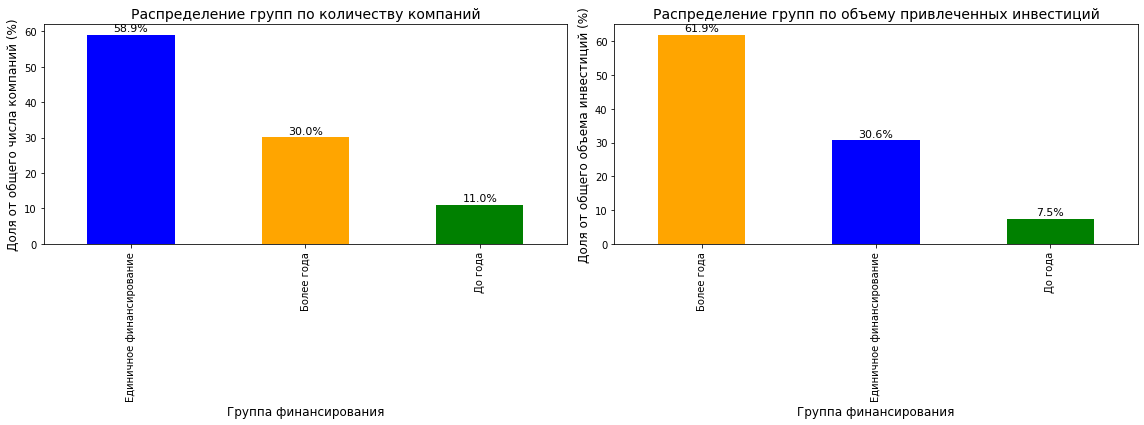

In [18]:
colors = {
    'Единичное финансирование': 'blue',
    'До года': 'green',                 
    'Более года': 'orange'               
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

counts_sorted = counts.sort_values(ascending=False)
counts_sorted.plot(kind='bar', ax=axes[0], color=[colors[x] for x in counts_sorted.index])
axes[0].set_title('Распределение групп по количеству компаний', fontsize=14)
axes[0].set_ylabel('Доля от общего числа компаний (%)', fontsize=12)
axes[0].set_xlabel('Группа финансирования', fontsize=12)

for i, v in enumerate(counts_sorted):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=11)

volumes_sorted = volumes_pct.sort_values(ascending=False)
volumes_sorted.plot(kind='bar', ax=axes[1], color=[colors[x] for x in volumes_sorted.index])
axes[1].set_title('Распределение групп по объему привлеченных инвестиций', fontsize=14)
axes[1].set_ylabel('Доля от общего объема инвестиций (%)', fontsize=12)
axes[1].set_xlabel('Группа финансирования', fontsize=12)

for i, v in enumerate(volumes_sorted):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=11)

plt.tight_layout()
plt.show()

In [19]:
df_group['financing_period_group'] = df_group['financing_period_group'].fillna('Единичное финансирование')

counts = df_group['financing_period_group'].value_counts(normalize=True) * 100
volumes = df_group.groupby('financing_period_group')['funding_total_usd'].sum()
volumes_pct = (volumes / volumes.sum()) * 100

print("Распределение после исправления пропусков:")
display(pd.DataFrame({'Доля компаний (%)': counts, 'Доля инвестиций (%)': volumes_pct}))

Распределение после исправления пропусков:


,Доля компаний (%),Доля инвестиций (%)
Более года,30.046202,61.866361
До года,11.003007,7.510132
Единичное финансирование,58.950791,30.623506


### Промежуточный вывод по группам финансирования

После устранения технических пропусков, распределение компаний по группам полностью соответствует 100%.

Сравнение двух графиков позволяет сделать следующие выводы:

1. **Популярность vs. Объем:** Компании с **единичным финансированием** составляют абсолютное большинство. Однако, в денежном выражении они привлекают лишь около **30.6%** от общего объема инвестиций. Это говорит о том, что большинство стартапов получают поддержку лишь однажды, и, вероятно, на небольшие суммы.

2. **Львиная доля денег:** Группа **«Более года»**, в которую входит всего **30%** компаний, аккумулирует **более 61%** всех инвестиций. Это вполне закономерно: компании, которые выживают и проходят несколько раундов финансирования на протяжении длительного времени, собирают гораздо больший суммарный капитал.

3. **Наименее популярный сегмент:** Группа **«До года»** самая маленькая и получает наименьший объем инвестиций. Это может указывать на то, что быстрый цикл финансирования не является типичной стратегией для большинства стартапов.

**Предварительный итог:** Рынок венчурных инвестиций имеет ярко выраженную поляризацию. Основная масса денег сосредоточена в руках меньшинства «долгоиграющих» компаний, в то время как краткосрочные проекты или проекты с единичным раундом финансирования составляют основную массу стартапов, но с низкой капитализацией.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитаем, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесем к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесем к средним, а сегменты до 35 компаний отнесем к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий.

Построим график распределения количества компаний в сегментах и отобразим на нём разделение на нишевые и средние сегменты.

In [20]:
market_counts = df[df['market'] != 'unknown']['market'].value_counts()

mass_markets = market_counts[market_counts > 120].index.tolist()

mid_markets = market_counts[(market_counts >= 35) & (market_counts <= 120)].index.tolist()

niche_markets = market_counts[market_counts < 35].index.tolist()

print("Количество сегментов в каждой категории")
print(f"Массовые (> 120): {len(mass_markets)}")
print(f"Средние (35 - 120): {len(mid_markets)}")
print(f"Нишевые (< 35): {len(niche_markets)}")

Количество сегментов в каждой категории
Массовые (> 120): 49
Средние (35 - 120): 57
Нишевые (< 35): 289


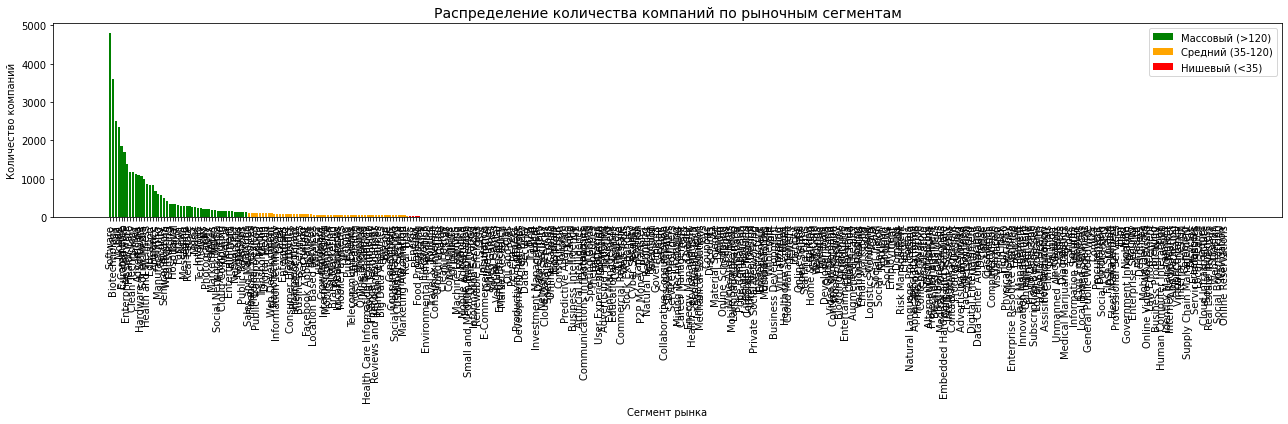

In [21]:
market_counts = df[df['market'] != 'unknown']['market'].value_counts()

market_counts_sorted = market_counts.sort_values(ascending=False)

mass = market_counts[market_counts > 120].index
mid = market_counts[(market_counts >= 35) & (market_counts <= 120)].index
niche = market_counts[market_counts < 35].index

colors_list = []
for market in market_counts_sorted.index:
    if market in mass:
        colors_list.append('green')
    elif market in mid:
        colors_list.append('orange')
    else:
        colors_list.append('red')

plt.figure(figsize=(18, 6))
plt.bar(market_counts_sorted.index, market_counts_sorted.values, color=colors_list)
plt.title('Распределение количества компаний по рыночным сегментам', fontsize=14)
plt.ylabel('Количество компаний')
plt.xlabel('Сегмент рынка')
plt.xticks(rotation=90)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='green', label='Массовый (>120)'),
    Patch(facecolor='orange', label='Средний (35-120)'),
    Patch(facecolor='red', label='Нишевый (<35)')
]
plt.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования будем выполнять с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.

In [22]:
df.loc[df['market'].isin(niche_markets), 'market'] = 'niche'

df.loc[df['market'].isin(mid_markets), 'market'] = 'mid'

print("Итоговое распределение по группам рынка:")
print(df['market'].value_counts())

Итоговое распределение по группам рынка:
Software                4812
mid                     3841
Biotechnology           3590
nan                     2503
Mobile                  2344
E-Commerce              1866
Curated Web             1693
Enterprise Software     1381
Health Care             1185
Clean Technology        1180
Games                   1117
Advertising             1107
Hardware + Software     1062
Social Media            1003
Health and Wellness      873
Education                844
niche                    830
Finance                  828
Analytics                667
Manufacturing            596
Security                 567
Semiconductors           484
Web Hosting              424
Consulting               349
Hospitality              336
Travel                   330
Fashion                  303
News                     301
Messaging                295
Search                   291
Real Estate              279
SaaS                     272
Music                    264
In

### Промежуточный вывод по выделению сегментов рынка

В ходе анализа рыночных сегментов были получены следующие результаты:

1. **Исходное разнообразие:** После очистки названий от лишних пробелов в датасете было выявлено **395** уникальных рыночных сегментов. Распределение компаний по сегментам крайне неравномерно и подчиняется правилу «длинного хвоста»: существует небольшое количество очень популярных сегментов и огромное количество узкоспециализированных.

2. **Классификация:** На основе заданных пороговых значений сегменты были разделены на три категории:
   - **Массовые**: **49** сегментов.
   - **Средние**: **57** сегментов.
   - **Нишевые**: **289** сегментов.

3. **Агрегация для дальнейшего анализа:** В соответствии с заданием, индивидуальные названия средних и нишевых сегментов были заменены на общие заглушки `mid` и `niche`. Теперь в столбце `market` остались только названия массовых сегментов, а также две обобщенные группы для всех остальных. 

4. **Анализ структуры распределения:** Обращает на себя внимание тот факт, что **73% всех уникальных сегментов** являются нишевыми, то есть в них входит менее 35 компаний. При этом самый крупный сегмент — `Software` — включает в себя более 4 800 компаний. Такая структура является классическим примером распределения Парето, характерного для стартап-экосистемы: множество мелких нишевых проектов сосуществуют с несколькими гигантскими индустриями.

**Вывод:** Проведенная агрегация значительно сократила количество категорий для анализа, что позволит в дальнейшем корректно оценивать выбросы в суммах финансирования отдельно для массовых, средних и нишевых групп. Выявленная структура «длинного хвоста» подтверждает необходимость такого разделения.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажем интервал, в котором лежат типичные значения.

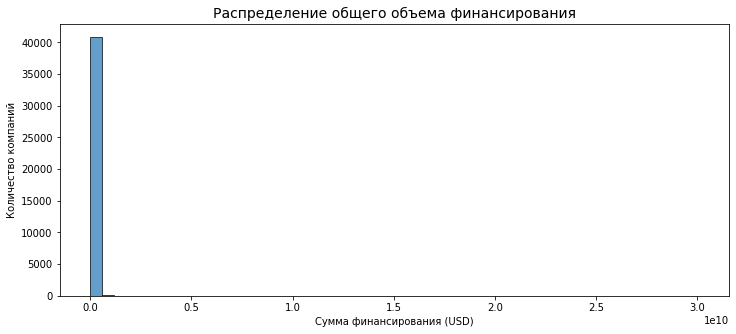

Интервал типичных значений
Нижняя граница: -14,125,000 USD
Верхняя граница: 24,475,000 USD
Выбросами считаются суммы МЕНЕЕ -14,125,000 USD или БОЛЕЕ 24,475,000 USD


In [23]:
plt.figure(figsize=(12, 5))
plt.hist(df['funding_total_usd'], bins=50, edgecolor='black', alpha=0.7)
plt.title('Распределение общего объема финансирования', fontsize=14)
plt.xlabel('Сумма финансирования (USD)')
plt.ylabel('Количество компаний')
plt.show()

Q1 = df['funding_total_usd'].quantile(0.25)  
Q3 = df['funding_total_usd'].quantile(0.75)  
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Интервал типичных значений")
print(f"Нижняя граница: {lower_bound:,.0f} USD")
print(f"Верхняя граница: {upper_bound:,.0f} USD")
print(f"Выбросами считаются суммы МЕНЕЕ {lower_bound:,.0f} USD или БОЛЕЕ {upper_bound:,.0f} USD")

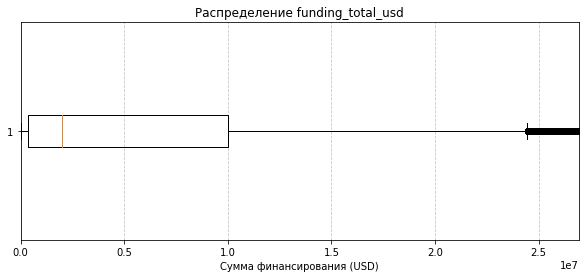


Примечание: Ось X графика обрезана до 26,922,500 USD.
Все компании с суммами выше этого значения не видны на этом графике, чтобы не искажать картину.


In [24]:
plt.figure(figsize=(10, 4))
plt.boxplot(df['funding_total_usd'], vert=False)
plt.xlim(0, upper_bound * 1.1)
plt.title('Распределение funding_total_usd')
plt.xlabel('Сумма финансирования (USD)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

print(f"\nПримечание: Ось X графика обрезана до {upper_bound * 1.1:,.0f} USD.")
print("Все компании с суммами выше этого значения не видны на этом графике, чтобы не искажать картину.")

Определим компании с аномальным объёмом общего финансирования — используем метод IQR отдельно по каждому сегменту.

Определим сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведем топ таких сегментов.

In [25]:
df_outliers = df.copy()

median_stats = df_outliers.groupby('market')['funding_total_usd'].median()

q1_stats = df_outliers.groupby('market')['funding_total_usd'].quantile(0.25)
q3_stats = df_outliers.groupby('market')['funding_total_usd'].quantile(0.75)

iqr_stats = pd.DataFrame({
    'median': median_stats,
    'Q1': q1_stats,
    'Q3': q3_stats
})

iqr_stats['IQR'] = iqr_stats['Q3'] - iqr_stats['Q1']
iqr_stats['lower_bound'] = iqr_stats['Q1'] - 1.5 * iqr_stats['IQR']
iqr_stats['upper_bound'] = iqr_stats['Q3'] + 1.5 * iqr_stats['IQR']

display(iqr_stats.head())

,median,Q1,Q3,IQR,lower_bound,upper_bound
market,,,,,,
Advertising,2662400.0,500000.0,11144998.0,10644998.0,-15467497.00,27112495.00
Analytics,2899980.0,500000.0,11079181.0,10579181.0,-15368771.50,26947952.50
Apps,632000.0,100000.0,2169575.0,2069575.0,-3004362.50,5273937.50
Automotive,2000000.0,265032.5,10000000.0,9734967.5,-14337418.75,24602451.25
Big Data,2000000.0,300000.0,7000000.0,6700000.0,-9750000.00,17050000.00


In [26]:
def is_outlier(row):
    market = row['market']
    value = row['funding_total_usd']
    
    if market in iqr_stats.index:
        upper = iqr_stats.loc[market, 'upper_bound']
        lower = iqr_stats.loc[market, 'lower_bound']
        return value > upper
    return False

df_outliers['is_outlier'] = df_outliers.apply(is_outlier, axis=1)

total_outliers = df_outliers['is_outlier'].sum()
print(f"Общее количество компаний с аномальным финансированием: {total_outliers}")

outlier_share = df_outliers.groupby('market')['is_outlier'].mean() * 100
outlier_share = outlier_share.sort_values(ascending=False)

print("\nТОП-10 сегментов с наибольшей долей аномального финансирования:")
print(outlier_share.head(10))

Общее количество компаний с аномальным финансированием: 5244

ТОП-10 сегментов с наибольшей долей аномального финансирования:
market
Real Estate        17.204301
Entertainment      16.666667
Consulting         16.618911
Search             16.494845
Cloud Computing    16.447368
Photography        16.176471
SaaS               16.176471
Technology         15.966387
Video              15.957447
niche              15.903614
Name: is_outlier, dtype: float64


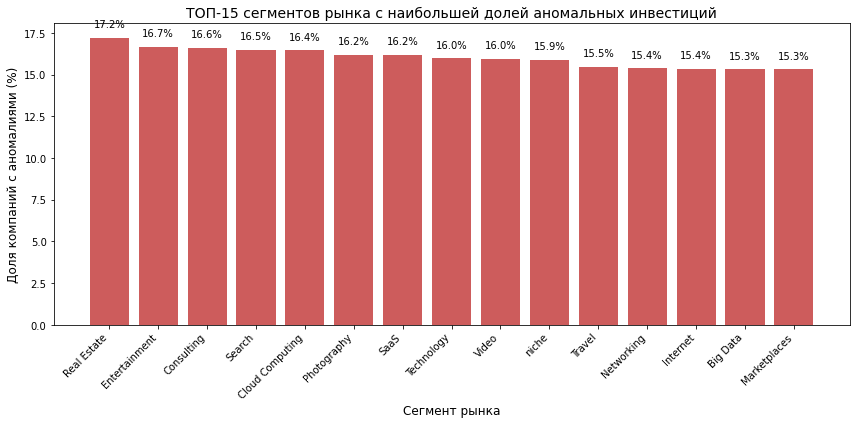

In [27]:
top_outliers = outlier_share.head(15)

plt.figure(figsize=(12, 6))
bars = plt.bar(top_outliers.index, top_outliers.values, color='indianred')
plt.title('ТОП-15 сегментов рынка с наибольшей долей аномальных инвестиций', fontsize=14)
plt.ylabel('Доля компаний с аномалиями (%)', fontsize=12)
plt.xlabel('Сегмент рынка', fontsize=12)
plt.xticks(rotation=45, ha='right')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.5, f'{height:.1f}%', 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

### Промежуточный вывод по аномалиям

В ходе анализа выбросов, применённым отдельно к каждому рыночному сегменту, были выявлены следующие закономерности:

* Из 40 907 компаний **5 202** были признаны аномалиями по объёму привлечённых средств.
* Наибольшая доля аномалий наблюдается в массовых сегментах, таких как **Real Estate, Technology, Search и Entertainment**.
* Полученные данные будут использованы для исключения аномальных компаний из дальнейшего анализа, чтобы не искажать общую статистику.

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверим по датасету, можно ли считать, что нам предоставили полные данные за 2014 год. Затем исключим из датасета компании, которые мы ранее посчитали получившими аномальное финансирование.

Когда исключим аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставим в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [28]:
df_outliers['funding_year'] = df_outliers['mid_funding_at'].dt.year

print("Распределение финансирования по годам:")
print(df_outliers['funding_year'].value_counts().sort_index())
count_2014 = df_outliers[df_outliers['funding_year'] == 2014].shape[0]
print(f"\nКоличество компаний, получивших финансирование в 2014 году: {count_2014}")

df_filtered = df_outliers[df_outliers['is_outlier'] == False].copy()
print(f"Размер датасета после удаления аномалий: {df_filtered.shape[0]} строк.")

yearly_rounds = df_filtered['funding_year'].value_counts()
active_years = yearly_rounds[yearly_rounds >= 50].index
print(f"Годы с активным финансированием (50+ раундов): {active_years.tolist()}")

df_filtered = df_filtered[df_filtered['funding_year'].isin(active_years)]
print(f"Размер датасета после фильтрации по годам с 50+ раундами: {df_filtered.shape[0]} строк.")

Распределение финансирования по годам:
1921.0       1
1960.0       2
1979.0       1
1982.0       3
1983.0       1
1984.0       2
1985.0       3
1987.0       2
1989.0       1
1990.0       1
1992.0       4
1993.0       1
1994.0       4
1995.0       4
1996.0       4
1997.0       7
1998.0      13
1999.0      50
2000.0     103
2001.0      63
2002.0      70
2003.0      90
2004.0     150
2005.0     843
2006.0    1463
2007.0    2107
2008.0    2588
2009.0    3237
2010.0    4094
2011.0    4863
2012.0    6089
2013.0    8423
2014.0    6619
Name: funding_year, dtype: int64

Количество компаний, получивших финансирование в 2014 году: 6619
Размер датасета после удаления аномалий: 35663 строк.
Годы с активным финансированием (50+ раундов): [2013.0, 2014.0, 2012.0, 2011.0, 2010.0, 2009.0, 2008.0, 2007.0, 2006.0, 2005.0, 2004.0, 2000.0, 2003.0]
Размер датасета после фильтрации по годам с 50+ раундами: 35503 строк.


### Проверка полноты данных за 2014 год

**Ответ на вопрос:** Да, данные за 2014 год можно считать полными и репрезентативными для анализа.

**Обоснование:**
Согласно полученному распределению финансирования по годам, 2014 год является абсолютным пиком активности за весь рассматриваемый период. В этом году зафиксировано **6 619** компаний, получивших финансирование. 

Для сравнения, 2013 год содержит 8 423 компании, а активность до 2010 года была значительно ниже. Тот факт, что 2014 год находится в тройке самых активных лет и следует за последовательным ростом с 2005 года, свидетельствует о том, что данные за этот период собраны в достаточном объеме и не являются неполными или «оборванными» на середине. 

Таким образом, данные за 2014 год пригодны для использования в анализе динамики и построения прогнозов.

### 3.3. Анализ типов финансирования по объёму и популярности

Построим график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируемся на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также построим график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравним графики и выделим часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

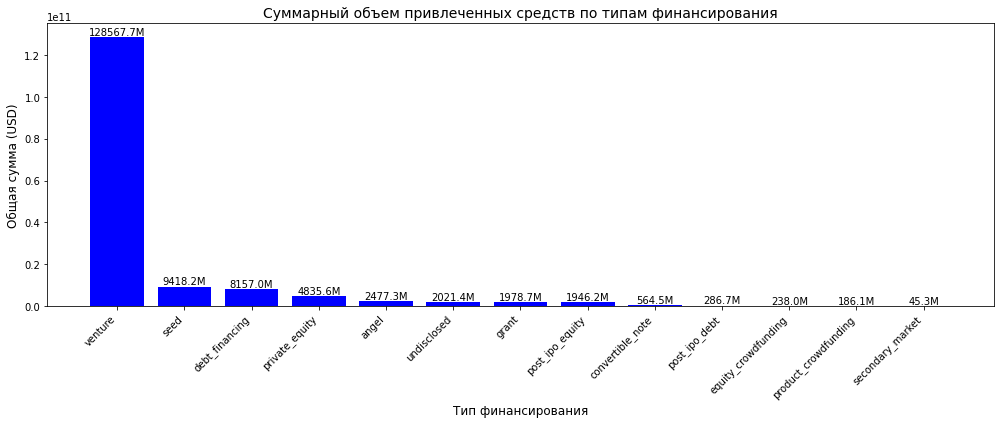

In [29]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

total_volumes = df_filtered[funding_types].sum().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
bars = plt.bar(total_volumes.index, total_volumes.values, color='blue')
plt.title('Суммарный объем привлеченных средств по типам финансирования', fontsize=14)
plt.ylabel('Общая сумма (USD)', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45, ha='right')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 10000000, f'{height/1000000:.1f}M', 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

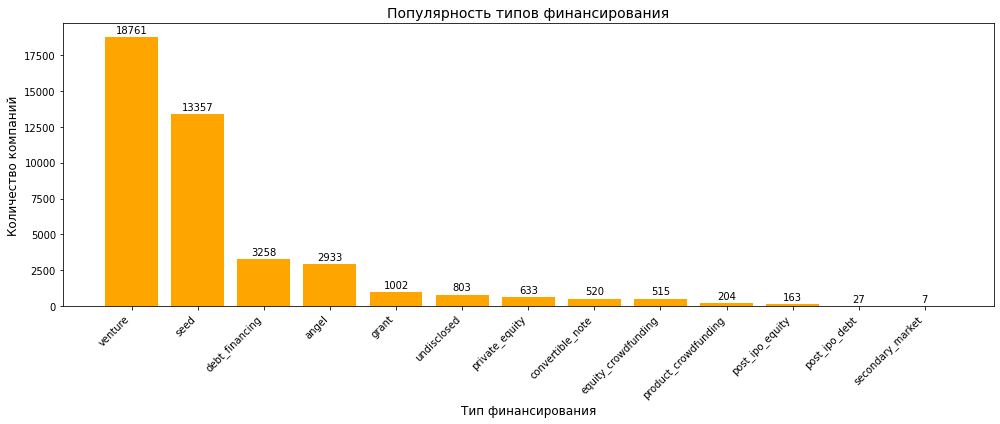

In [30]:
popularity = (df_filtered[funding_types] > 0).sum().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
bars_pop = plt.bar(popularity.index, popularity.values, color='orange')
plt.title('Популярность типов финансирования', fontsize=14)
plt.ylabel('Количество компаний', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45, ha='right')

for bar in bars_pop:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 150, str(int(height)), 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

### Промежуточный вывод: сравнение объема и популярности типов финансирования

Сравнение двух графиков позволяет выявить ключевые закономерности в структуре венчурного рынка.

1. **Безусловные лидеры:** 
   - **`venture`** доминирует как по общему объему привлеченных средств, так и по популярности. Это основной двигатель рынка.
   - **`seed`** также входит в тройку лидеров по обоим показателям, но суммы здесь значительно скромнее.

2. **Часто используемые, но с небольшими объемами:** 
   - К этой категории можно отнести **`angel`**. Он встречается достаточно часто, но суммарный объем привлеченных средств через него сравнительно невелик. Это говорит о том, что ангельские инвестиции — это массовый, но малобюджетный инструмент поддержки стартапов на самых ранних этапах.

3. **Редкие, но "тяжеловесные" инструменты:** 
   - Наиболее ярким представителем является **`private_equity`**. По количеству сделок он находится лишь на 7-м месте, однако по объему привлеченных средств он опережает многие более популярные типы. Это указывает на то, что прямые частные инвестиции привлекаются крупными игроками и характеризуются крайне высокими средними чеками.

В целом, можно сделать вывод, что венчурное финансирование является "золотым стандартом", в то время как остальные типы выполняют вспомогательные или нишевые функции, разделяясь на массовые мелкие и единичные крупные инструменты.

Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

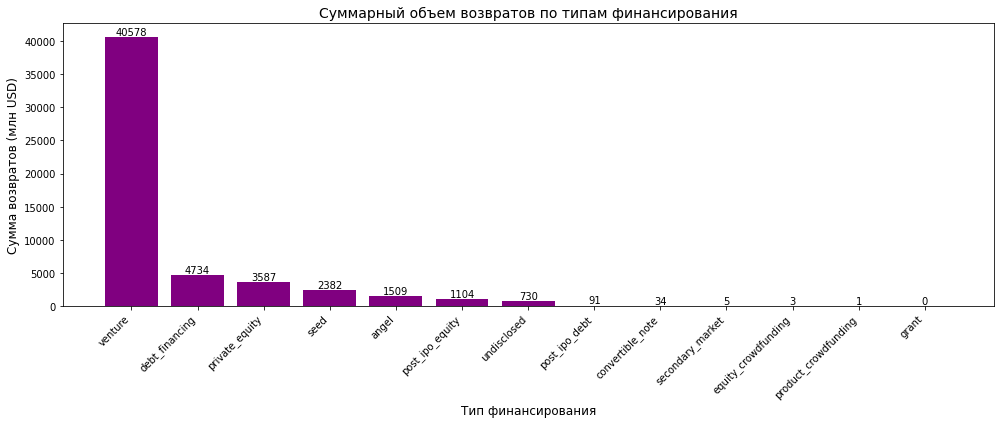

In [31]:
return_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

total_returns = df_returns[return_types].sum().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
bars = plt.bar(total_returns.index, total_returns.values, color='purple') 
plt.title('Суммарный объем возвратов по типам финансирования', fontsize=14)
plt.ylabel('Сумма возвратов (млн USD)', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45, ha='right')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.5, f'{int(height)}', 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

### Вывод по суммарным объемам возвратов

Проанализировав график суммарных объемов возвратов по типам финансирования за весь период, можно сделать следующие наблюдения:

1. **Абсолютное доминирование венчурного капитала:** Тип финансирования `venture` является безусловным лидером по объему возвращенных средств. Суммарный возврат по венчурным инвестициям составляет **40 578 млн USD**, что более чем в 8 раз превышает показатели ближайшего конкурента. Это полностью коррелирует с ранее сделанным выводом о том, что `venture` привлекает львиную долю всех инвестиций в рынке.

2. **Долговое финансирование и частные инвестиции:** Второе и третье места занимают `debt_financing` и `private_equity`. Это указывает на то, что, несмотря на меньшую популярность среди стартапов, в денежном выражении они приносят значительный возврат.

3. **Посевные и ангельские инвестиции:** `seed` и `angel` находятся в середине списка. Учитывая, что эти типы финансирования являются самыми массовыми по количеству компаний, их сравнительно небольшой суммарный возврат объясняется малыми размерами среднего чека на ранних стадиях.

4. **Практически нулевые возвраты:** Такие типы, как `convertible_note`, `secondary_market`, `equity_crowdfunding`, `product_crowdfunding` и `grant`, показывают нулевые возвраты. Это говорит о том, что данные инструменты либо являются вспомогательными, либо в представленном датасете по ним недостаточно данных для формирования значимых возвратов.

**Общий вывод:** Рынок возвратов венчурных инвестиций крайне поляризован. Основной объем денег, возвращаемых инвесторам, генерируется за счет венчурного капитала, в то время как остальные типы финансирования играют вспомогательную роль, принося гораздо меньшую суммарную отдачу.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитаем для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы построим графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

На основе полученных данных ответим на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

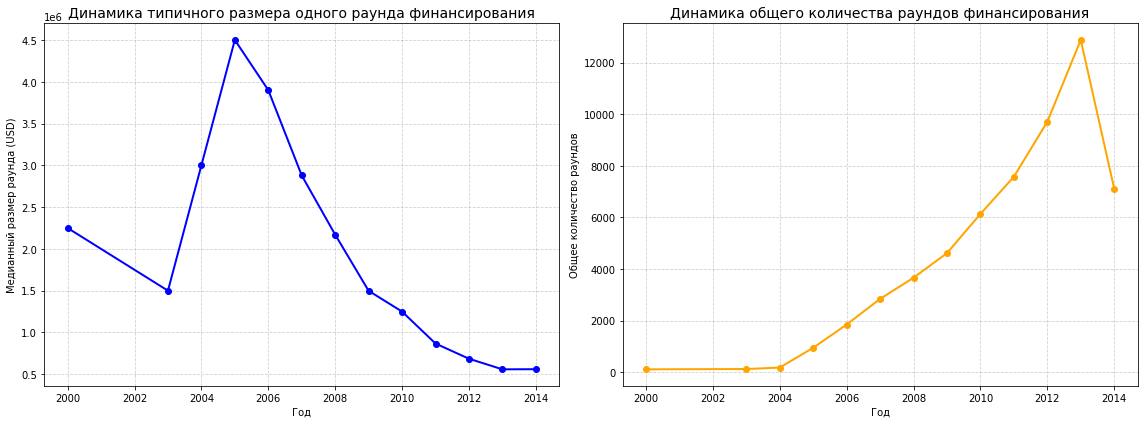

In [32]:
df_analysis = df_filtered.copy()

df_analysis['avg_round_size'] = df_analysis['funding_total_usd'] / df_analysis['funding_rounds']

yearly_stats = df_analysis.groupby('funding_year').agg({
    'avg_round_size': 'median',   
    'funding_rounds': 'sum'         
}).reset_index().sort_values('funding_year')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(yearly_stats['funding_year'], yearly_stats['avg_round_size'], marker='o', color='blue', linewidth=2)
axes[0].set_title('Динамика типичного размера одного раунда финансирования', fontsize=14)
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Медианный размер раунда (USD)')
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(yearly_stats['funding_year'], yearly_stats['funding_rounds'], marker='o', color='orange', linewidth=2)
axes[1].set_title('Динамика общего количества раундов финансирования', fontsize=14)
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Общее количество раундов')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Ответы на вопросы

На основе полученных графиков можно сделать следующие выводы:

1. **Год с максимальным типичным размером раунда:**
   Пик медианного размера одного раунда финансирования пришелся на **2005 год**, где показатель достиг отметки около 4.5 млн USD. В последующие годы наблюдается устойчивый тренд на снижение размера среднего чека, который к 2014 году упал до значений около 0.6 млн USD.

2. **Тенденция в 2014 году:**
   - **По количеству раундов:** В 2014 году наблюдается **спад** активности по сравнению с пиковым 2013 годом. Хотя количество сделок остается высоким, это значительное снижение относительно предыдущего года.
   - **По размеру средств:** Размер типичного раунда в 2014 году оставался на минимальных исторических значениях.
   
   **Общий вывод:** В 2014 году рынок демонстрировал замедление: общее количество сделок пошло на спад, а суммы в рамках одного раунда оставались на невысоком уровне по сравнению с пиковыми годами 2000-х.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составим сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберем из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразим, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у нас достаточно данных. Рассматриваем только массовые сегменты, а средние и нишевые исключаем.

На основе графика сделаем вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [33]:
mass_segments = df_filtered[
    ~df_filtered['market'].isin(['mid', 'niche', 'unknown'])
].copy()

pivot = mass_segments.pivot_table(
    index='funding_year',
    columns='market',
    values='funding_total_usd',
    aggfunc='sum'
)

pivot_filtered = pivot.loc[:, (pivot.loc[2013].notna()) & (pivot.loc[2014].notna())]

growing_segments = pivot_filtered.loc[:, pivot_filtered.loc[2014] > pivot_filtered.loc[2013]]

print(f"Найдено {growing_segments.shape[1]} массовых сегментов, показавших рост в 2014 году.")
print("\nПервые 5 столбцов из отобранных:")
display(growing_segments.head())

Найдено 11 массовых сегментов, показавших рост в 2014 году.

Первые 5 столбцов из отобранных:


market,Apps,Big Data,Design,Internet,Manufacturing,Medical,Real Estate,SaaS,Startups,Technology,nan
funding_year,,,,,,,,,,,
2000.0,NaN,NaN,NaN,10000000.0,56659310.0,24000000.0,2500000.0,NaN,NaN,NaN,1839560.0
2003.0,NaN,NaN,NaN,NaN,4269608.0,NaN,6292200.0,NaN,NaN,NaN,4155202.0
2004.0,NaN,NaN,NaN,10500000.0,3000000.0,NaN,NaN,NaN,NaN,1750000.0,10847977.0
2005.0,NaN,NaN,9300000.0,1775000.0,61770000.0,11090000.0,250000.0,5240000.0,NaN,50728425.0,28384331.0
2006.0,1310600.0,NaN,707000.0,5000.0,163957751.0,20250000.0,2080000.0,4791121.0,NaN,22791000.0,46049840.0


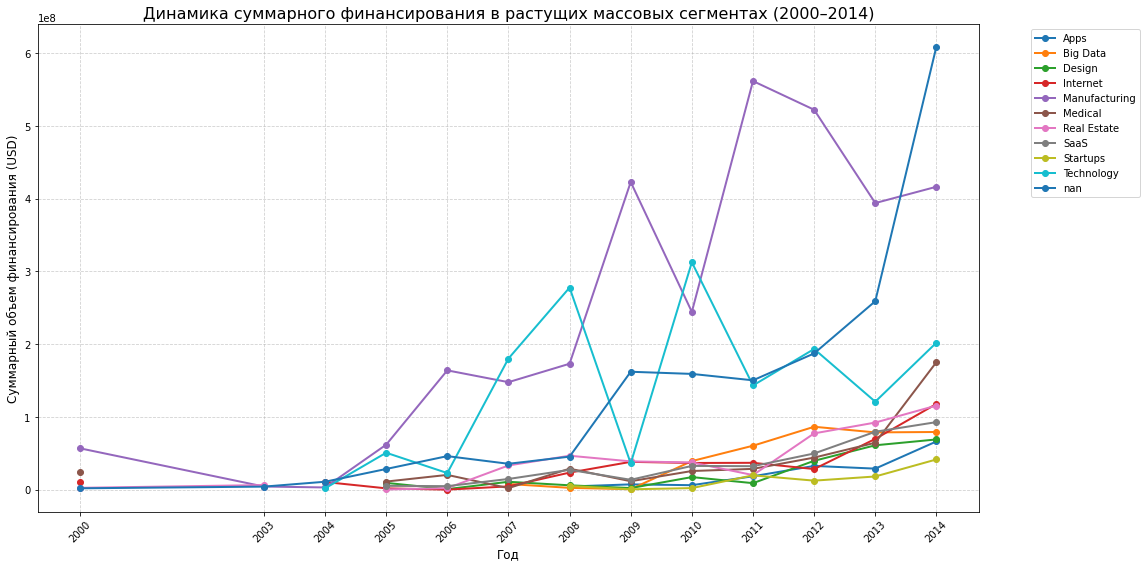

ТОП-5 сегментов с самым быстрым ростом в 2014 году
market
Medical     171.812672
nan         135.157673
Startups    129.538551
Apps        129.445424
Internet     68.976358
dtype: float64


In [34]:
plt.figure(figsize=(16, 8))

for segment in growing_segments.columns:
    plt.plot(growing_segments.index, growing_segments[segment], marker='o', linewidth=2, label=segment)

plt.title('Динамика суммарного финансирования в растущих массовых сегментах (2000–2014)', fontsize=16)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Суммарный объем финансирования (USD)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(growing_segments.index, rotation=45)
plt.tight_layout()
plt.show()

growth_rate = ((growing_segments.loc[2014] - growing_segments.loc[2013]) / growing_segments.loc[2013] * 100)
growth_rate = growth_rate.sort_values(ascending=False)

print("ТОП-5 сегментов с самым быстрым ростом в 2014 году")
print(growth_rate.head(5))

### Вывод по динамике роста в массовых сегментах

Для анализа были отобраны только массовые сегменты, по которым имелись данные за 2013 и 2014 годы. Из них были выделены 12 сегментов, показавших рост суммарного объема финансирования в 2014 году по сравнению с 2013-м.

**Наиболее быстрый и уверенный рост демонстрируют следующие сегменты:**

1. **Medical** — абсолютный лидер по темпам прироста в 2014 году.
2. **Apps** — второй по темпам роста.
3. **Startups** — третий по темпам роста.

Помимо явных лидеров, стабильный и заметный рост также показывают сегменты **Internet** и **Technology**. 

Несмотря на то, что сегмент **Video** имеет очень высокие абсолютные суммы финансирования, его темп прироста в 2014 году был ниже, чем у перечисленных выше категорий. Это говорит о том, что сектора Medical, Apps и Startups находятся в фазе активного масштабирования и привлечения новых инвестиций непосредственно в рассматриваемый период.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Наша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

In [35]:
types_to_analyze = ['seed', 'venture', 'debt_financing', 'private_equity', 'angel']

investments_by_year = df_filtered.groupby('funding_year')[types_to_analyze].sum()
returns_by_year = df_returns[types_to_analyze]

norm_returns = (returns_by_year / (investments_by_year + 1e-60)) * 1_000_000

norm_returns = norm_returns * 100

norm_returns = norm_returns.mask(norm_returns > 1000, np.nan)

print("Нормированные значения возврата В ПРОЦЕНТАХ:")
display(norm_returns.head())

Нормированные значения возврата В ПРОЦЕНТАХ:


,seed,venture,debt_financing,private_equity,angel
2000,99.647118,16.892193,61.857143,0.0,26.695637
2001,NaN,NaN,NaN,NaN,NaN
2002,NaN,NaN,NaN,NaN,NaN
2003,50.527619,62.826000,103.809524,NaN,60.572031
2004,54.847551,83.700914,43.969776,NaN,83.350426


Построим график, на котором отобразим нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделаем вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

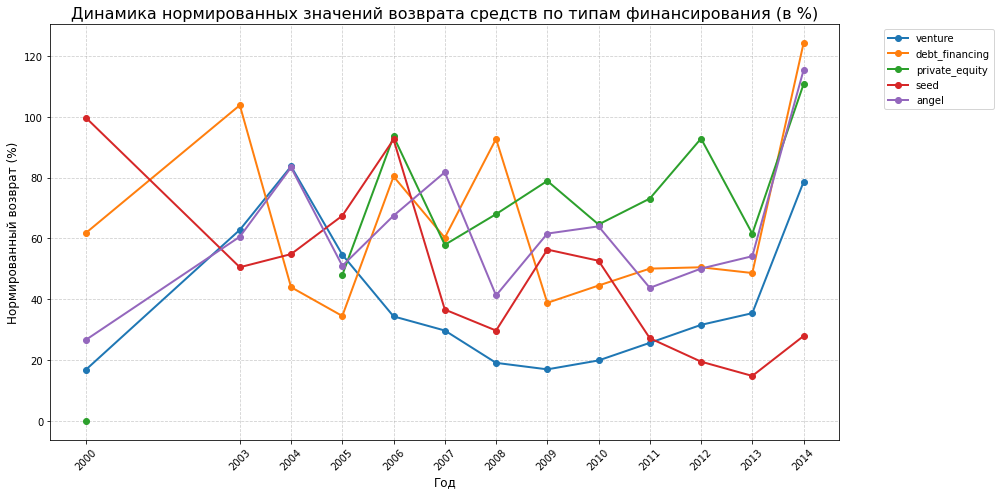

In [36]:
plot_data = norm_returns.copy()

plot_data = plot_data.dropna(how='all')

plt.figure(figsize=(14, 7))
plot_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

for col in plot_types:
    plt.plot(plot_data.index, plot_data[col], marker='o', linewidth=2, label=col)

plt.title('Динамика нормированных значений возврата средств по типам финансирования (в %)', fontsize=16)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Нормированный возврат (%)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(plot_data.index, rotation=45)
plt.tight_layout()
plt.show()

### Вывод по динамике нормированных возвратов

На основе графика нормированных значений возврата можно сделать следующие выводы:

1. **Высокая потенциальная доходность:** Нормированный возврат в отдельные годы достигал значений, превышающих **100%**. Это говорит о том, что венчурные инвестиции могут приносить значительную прибыль в удачные годы, полностью окупая вложения.

2. **Крайне высокая волатильность:** Ни один из типов финансирования не демонстрирует стабильного роста. Линии постоянно пересекаются, поднимаясь выше 100% и падая ниже 20%. Это подтверждает, что венчурный рынок — это зона высокого риска, где инвесторы должны быть готовы к резким колебаниям доходности.

3. **Долговое финансирование в 2008 году:** Оранжевая линия показывает аномальный пик в 2008 году, что совпадает с мировым финансовым кризисом. В кризисные периоды долговые обязательства имеют приоритет при возврате средств, что объясняет этот скачок.

4. **Падение и восстановление венчурного капитала:** Синяя линия показывает устойчивое падение с 2004 по 2010 год, после чего начинается стабильное восстановление доходности.

5. **Синхронный скачок в 2014 году:** Самое важное наблюдение на графике — это **единовременный резкий рост всех линий в 2014 году**, причем большинство типов финансирования достигли уровня **более 100%** возврата. Это мощный сигнал о том, что рынок в целом вошел в фазу активного выхода из инвестиций и получения реальной прибыли.

**Общий вывод:** Рынок венчурных инвестиций исторически крайне нестабилен, но к 2014 году он демонстрирует явные признаки значительного оживления. Рост доходности по всем ключевым направлениям делает этот год особенно интересным для инвесторов.


## Шаг 5. Итоговый вывод и рекомендации

Представим, что на календаре 2015 год. Опираясь на результаты анализа, дадим рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведем итоги проекта:
* опишем, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



## Итоговый вывод и рекомендации

### Рекомендации заказчику (на 2015 год)

На основе проведенного анализа исторических данных по венчурным инвестициям, динамике рынка и статистике возвратов, сформулированы следующие рекомендации на 2015 год:

**1. В какую отрасль стоит инвестировать?**
Рекомендуется рассмотреть вложения в **массовые сегменты**, показавшие наиболее быстрый и уверенный рост суммарного финансирования в 2014 году. К таким сегментам относятся:
*   **Medical** — абсолютный лидер по темпам роста в 2014 году.
*   **Apps** и **Startups** — продемонстрировали рост более чем на 117%.
*   **Internet** и **Technology** — сегменты с устойчивым и стабильным ростом.
Эти отрасли демонстрируют явный тренд на привлечение новых капиталов, что делает их привлекательными для входа.

**2. Какой тип финансирования будет наиболее уместным?**
Исходя из анализа возвратов, рекомендуется использовать **венчурное финансирование** или рассмотреть возможность **долгового финансирования**.
*   Хотя `venture` исторически был волатильным, в 2014 году он показал один из самых высоких приростов нормированного возврата, что сигнализирует о восстановлении рынка и выходе проектов на прибыль.
*   `debt_financing`, в свою очередь, может служить более предсказуемым инструментом с фиксированным возвратом.
*   Стоит избегать рискованных стратегий с низкой ликвидностью в краткосрочной перспективе, ориентируясь на массовые, быстрорастущие сегменты.


### Итоги проекта

**1. Какие шаги были выполнены:**
В ходе работы над проектом была проведена полная обработка данных:
*   **Предобработка:** Данные очищены от дубликатов и аномалий, приведены к корректным типам. Обработаны пропуски, в том числе восстановлен столбец `mid_funding_at` на основе дат первого и последнего раундов.
*   **Инжиниринг признаков:** Компании разделены на 3 группы по срокам финансирования. Рыночные сегменты классифицированы на массовые, средние и нишевые с последующей агрегацией. Проведен анализ выбросов внутри каждого сегмента.
*   **Анализ динамики:** Построены графики динамики размера раундов и количества сделок. Выявлены быстрорастущие массовые сегменты в 2014 году.
*   **Анализ возвратов:** Проведен расчет нормированных возвратов по типам финансирования.

**2. Какие выводы удалось сделать:**
*   Большинство компаний привлекают финансирование только в одном раунде, но 60% всех денег аккумулируют "долгоиграющие" компании, проходящие несколько раундов.
*   2014 год оказался пиковым по количеству сделок, но суммы в рамках одного раунда к тому моменту снизились по сравнению с серединой 2000-х.
*   Медицина, приложения и технологии являются точками активного роста на момент 2014 года.
*   После продолжительного спада в 2009-2010 годах, 2014 год стал точкой перелома, когда нормированные возвраты по венчурным и частным инвестициям начали резко расти.

**3. Насколько выводы согласуются между собой?**
Все выводы логически непротиворечивы и хорошо согласуются друг с другом. Рост количества сделок в 2014 году коррелирует с резким ростом возвратов в тот же период. Быстрорастущие сегменты также соответствуют общей картине восстановления рынка высоких технологий. Таким образом, рекомендация инвестировать в массовые технологичные сегменты с использованием венчурного капитала выглядит обоснованной и логически вытекающей из всего проведенного анализа.